# 2 · Build the model

**Goal:** the best accuracy from a network **no bigger than the baseline** (26,522
parameters) that trains in **about 90 seconds on GitHub**. The baseline gets 76.3%.
This folder is the demo submission that this notebook builds.

**The rule:** every setting in `model.py` is chosen by an experiment in this notebook, not
copied from a recipe. Each section asks a question, runs an experiment, and decides.

**How to read this:** the text and the plots tell the story. Cells starting with
`# Helper:` do one job, described on their first line; skim them if you like.
It takes about 15 minutes on a Mac with an Apple chip and about several hours without one,
so you may prefer to read the saved results and rerun only the parts you change.

### Words we use

- **Parameters** (or *weights*): the numbers a network learns. Our budget: 26,522 of them.
- **Loss**: how wrong the network is, as one number. Lower is better. Training nudges the
  parameters, step by step, to lower it.
- **Batch**: the images used for one nudge (one *step*). **Epoch**: one pass over all
  training images.
- **Learning rate**: how big each nudge is.
- **Seed**: the starting point for everything random (the first weights, the order of the
  images). The same seed gives the same run.
- **Check accuracy**: the share of right answers on images the network never trained on.

### How we avoid fooling ourselves

We choose settings using the images split with `seed=1`: learn from 80%, check on 20%. If you
try 20 settings and keep the best, part of its lead is luck on those particular check
images. So at the very end, `uv run score` checks the final model on a **different** split
(`seed=7`), images that played no part in any choice.

In [1]:
import copy
import importlib
import math
import statistics
import time
from dataclasses import dataclass, replace

import matplotlib.pyplot as plt
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F

from eurosat import data  # the only course code we use: it loads the images

plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.precision", 3)
torch.set_num_threads(4)  # GitHub's computer has 4 cores, so we time the CPU the same way

BUDGET_PARAMETERS = 26_522  # the baseline's size
BUDGET_SECONDS = 90  # training time on GitHub

full = data.train_set()
tune_train, tune_check = data.split_for_check(full, seed=1)
print(f"learn from {len(tune_train):,} images, check on {len(tune_check):,}")

learn from 17,280 images, check on 4,320


## 1 · Where we start

We start from the baseline (`submissions/baseline`). Let's see where it spends its parameters and its
work. For every layer, the table shows the size of its output (channels, rows, columns),
its parameters, and its **multiply-adds**: how many multiplications it does per image.

In [2]:
def baseline():  # the network of submissions/baseline/model.py
    return nn.Sequential(
        nn.Conv2d(3, 8, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(8, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Flatten(), nn.Linear(32 * 8 * 8, 10),
    )  # fmt: skip


def layer_table(net):
    # Helper: run one image through the network and list each layer's size and work.
    rows, name_of = [], {module: name for name, module in net.named_modules()}

    def record(module, inputs, output):
        weights = sum(p.numel() for p in module.parameters(recurse=False))
        if isinstance(module, nn.Conv2d):
            work = output.numel() * module.in_channels * math.prod(module.kernel_size)
        elif isinstance(module, nn.Linear):
            work = module.in_features * module.out_features
        else:
            work = 0
        rows.append({"layer": f"{name_of[module]} {type(module).__name__}",
                     "output": tuple(output.shape[1:]), "parameters": weights,
                     "multiply-adds": work})  # fmt: skip

    hooks = [m.register_forward_hook(record) for m in net.modules() if not list(m.children())]
    with torch.no_grad():
        net.eval()(torch.zeros(1, 3, 64, 64))
    for hook in hooks:
        hook.remove()
    table = pd.DataFrame(rows).set_index("layer")
    for column in ("parameters", "multiply-adds"):
        table[f"{column} %"] = (100 * table[column] / table[column].sum()).round(1)
    return table


layer_table(baseline())

,output,parameters,multiply-adds,parameters %,multiply-adds %
layer,,,,,
0 Conv2d,"(8, 64, 64)",224,884736,0.8,27.1
1 ReLU,"(8, 64, 64)",0,0,0.0,0.0
2 MaxPool2d,"(8, 32, 32)",0,0,0.0,0.0
3 Conv2d,"(16, 32, 32)",1168,1179648,4.4,36.1
4 ReLU,"(16, 32, 32)",0,0,0.0,0.0
5 MaxPool2d,"(16, 16, 16)",0,0,0.0,0.0
6 Conv2d,"(32, 16, 16)",4640,1179648,17.5,36.1
7 ReLU,"(32, 16, 16)",0,0,0.0,0.0
8 MaxPool2d,"(32, 8, 8)",0,0,0.0,0.0


**77% of the parameters sit in the last layer** (`10 Linear`), which does less than 1% of the
work. It looks at an 8×8 map of 32 patterns and has a separate weight for every position:
"a road in the top-left corner means Highway" needs different weights than "a road in the
bottom-right corner". But a highway is a highway wherever it runs. **Averaging each pattern
over the whole image** first ("how much road is there?") needs only 32 × 10 weights, and
frees about 20,000 parameters for the layers that find patterns.

## 2 · The submission

This cell **is** the submission. Running it writes `model.py` next to this notebook; the cell
after it loads that file. Everything below calls `model.train(...)`, the code GitHub runs,
so what we measure is what we submit.

`Config` holds every setting. GitHub calls `train(train_set, log)` and so uses the defaults;
we call `model.train(train_set, log, model.Config(lr=0.03))` to try other values. The
defaults are the final choices; section 13 checks each against its experiment.

In [3]:
%%writefile model.py
"""Demo: a small convolutional network, built from the baseline step by step.

How it was built, and why each setting has its value: 2-build-model.ipynb.
That notebook's submission cell writes this file, so make your changes there.

GitHub calls train(train_set, log), which uses the defaults in Config.
The notebook calls train(train_set, log, Config(lr=0.03)) to try other values.
"""

import math
from collections.abc import Callable
from dataclasses import dataclass
from itertools import pairwise

import torch
from torch import nn
from torch.nn import functional as F


@dataclass(frozen=True)  # frozen: a setting cannot be changed by accident
class Config:
    widths: tuple[int, ...] = (16, 24, 32, 48)  # how many patterns each block looks for
    stem_stride: int = 2  # the first block moves 2 pixels at a time: 4x less work
    batch_norm: bool = True  # rescale each block's outputs while learning
    epochs: int = 11  # passes over all training images
    batch_size: int = 64  # images per learning step
    lr: float = 0.01  # learning rate: the largest step size
    weight_decay: float = 0.0  # pull weights toward 0 (off: it did not help here)
    augment: bool = True  # randomly turn and mirror images
    valid_images: int = 1000  # kept out of training, only to draw the validation curve
    device: str = "cpu"  # notebook only: "mps" trains on a Mac's GPU (GitHub has none)
    watch: Callable | None = None  # notebook only: gets (model, optimizer) to look inside


def block(channels_in: int, channels_out: int, stride: int, batch_norm: bool) -> nn.Sequential:
    """Find patterns, rescale them, keep the positive ones, halve the image size."""
    return nn.Sequential(
        # 3x3 windows; no bias with batch norm, which adds its own shift
        nn.Conv2d(channels_in, channels_out, 3, stride=stride, padding=1, bias=not batch_norm),
        nn.BatchNorm2d(channels_out) if batch_norm else nn.Identity(),
        nn.ReLU(),
        nn.MaxPool2d(2),
    )


def make_model(cfg: Config = Config()) -> nn.Sequential:
    sizes = [3, *cfg.widths]  # 3 colors come in; each block's output feeds the next one
    blocks = [
        block(c_in, c_out, cfg.stem_stride if i == 0 else 1, cfg.batch_norm)
        for i, (c_in, c_out) in enumerate(pairwise(sizes))  # (3, 16), (16, 32), ...
    ]
    return nn.Sequential(
        *blocks,
        nn.AdaptiveAvgPool2d(1),  # average each pattern over the whole image
        nn.Flatten(),
        nn.Linear(cfg.widths[-1], 10),  # one score per class
    )


def coin(x: torch.Tensor) -> torch.Tensor:
    """True for about half of the images in the batch x, at random."""
    return torch.rand(len(x), 1, 1, 1, device=x.device) < 0.5


def flip_and_turn(x: torch.Tensor) -> torch.Tensor:
    """Give each image one of its 8 versions: 4 quarter turns, each mirrored or not."""
    x = torch.where(coin(x), x.flip(3), x)  # mirror left-right
    x = torch.where(coin(x), x.flip(2), x)  # mirror top-bottom
    x = torch.where(coin(x), x.transpose(2, 3), x)  # swap rows and columns
    return x.contiguous()  # tidy the memory layout: a Mac GPU is 5x slower without it


def train(train_set, log, cfg: Config = Config()) -> nn.Module:
    images, labels = train_set.images.to(cfg.device), train_set.labels.to(cfg.device)

    # Keep a few images out of training, only to draw the validation curve.
    order = torch.randperm(len(images), device=cfg.device)
    valid, fit = order[: cfg.valid_images], order[cfg.valid_images :]
    log.validate_on(images[valid].cpu(), labels[valid].cpu())
    images, labels = images[fit], labels[fit]

    model = make_model(cfg).to(cfg.device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
    # One cycle: the step size grows to lr, then shrinks to almost nothing by the end.
    steps_per_epoch = math.ceil(len(images) / cfg.batch_size)
    schedule = torch.optim.lr_scheduler.OneCycleLR(
        optimizer, cfg.lr, epochs=cfg.epochs, steps_per_epoch=steps_per_epoch
    )
    if cfg.watch:
        cfg.watch(model, optimizer)

    for _ in range(cfg.epochs):
        model.train()
        # Totals stay on the device: reading a number back (.item()) makes Python wait
        # for the device, so we do that once per epoch instead of after every step.
        total_loss = torch.zeros((), device=cfg.device)
        correct = torch.zeros((), device=cfg.device)
        for batch in torch.randperm(len(images), device=cfg.device).split(cfg.batch_size):
            x = images[batch].float() / 255  # bytes 0-255 become decimals 0-1
            y = labels[batch]
            if cfg.augment:
                x = flip_and_turn(x)
            scores = model(x)
            loss = F.cross_entropy(scores, y)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            schedule.step()
            total_loss += loss.detach() * len(batch)
            correct += (scores.argmax(1) == y).sum()
        # log(model): GitHub checks the model on the validation images later, off the clock
        n = len(images)
        log(model, train_loss=total_loss.item() / n, train_accuracy=correct.item() / n)
    return model

Overwriting model.py


In [4]:
import model

model = importlib.reload(model)  # load the file the cell above just wrote

The experiments begin from a **starting point**, written out in full so that none of them
depends on the defaults above. It keeps what section 1 and notebook 1 suggest, and takes
everything else from the baseline, ready to be tested:

- **Average each channel over the image** instead of the big last layer.
- **Twice the channels** (16, 32, 64 instead of 8, 16, 32): they fit now.
- **Batch normalization** and **turning and mirroring** switched on, to be tested.
- The baseline's **learning rate** (0.003) and **batch size** (128), to be tested.

In [5]:
start = model.Config(
    widths=(16, 32, 64), stem_stride=1, batch_norm=True, epochs=10, batch_size=128,
    lr=0.003, weight_decay=0.0, augment=True, valid_images=1000,
)  # fmt: skip
layer_table(model.make_model(start))

,output,parameters,multiply-adds,parameters %,multiply-adds %
layer,,,,,
0.0 Conv2d,"(16, 64, 64)",432,1769472,1.8,15.8
0.1 BatchNorm2d,"(16, 64, 64)",32,0,0.1,0.0
0.2 ReLU,"(16, 64, 64)",0,0,0.0,0.0
0.3 MaxPool2d,"(16, 32, 32)",0,0,0.0,0.0
1.0 Conv2d,"(32, 32, 32)",4608,4718592,18.9,42.1
1.1 BatchNorm2d,"(32, 32, 32)",64,0,0.3,0.0
1.2 ReLU,"(32, 32, 32)",0,0,0.0,0.0
1.3 MaxPool2d,"(32, 16, 16)",0,0,0.0,0.0
2.0 Conv2d,"(64, 16, 16)",18432,4718592,75.7,42.1


The same budget, spent differently: the pattern-finding layers now hold 96% of the
parameters, and the last layer only 650. But the work per image grew 3.4 times (twice the
channels everywhere), so every epoch is slower. Section 4 measures by how much.

**Learn more:** [But what is a neural network?](https://www.youtube.com/watch?v=aircAruvnKk)
(3Blue1Brown video) · [Convolutional networks](https://cs231n.github.io/convolutional-networks/)
(Stanford CS231n notes) · [Network in Network](https://arxiv.org/abs/1312.4400) (the paper
that introduced averaging each channel over the image)

## 3 · Before training: catch bugs cheaply

Three checks that take seconds and catch bugs that would otherwise cost hours.

**The size.** Within the budget, or we stop here.

In [6]:
def parameters(cfg):
    return sum(p.numel() for p in model.make_model(cfg).parameters())


assert parameters(start) <= BUDGET_PARAMETERS, "over the parameter budget"
print(f"{parameters(start):,} parameters, budget {BUDGET_PARAMETERS:,}")

24,346 parameters, budget 26,522


**The first loss.** Before learning anything, a network should be unsure: about 10% for
each of the 10 classes. The loss for that is 2.30 (it is ln 10). Much higher would mean it
starts out confidently wrong and wastes the first part of training unlearning that.

In [7]:
torch.manual_seed(0)
net = model.make_model(start)
x, y = tune_train.images[:512].float() / 255, tune_train.labels[:512]
with torch.no_grad():
    first_loss = F.cross_entropy(net(x), y).item()
print(f"loss before training: {first_loss:.2f}   (knowing nothing: {math.log(10):.2f})")

loss before training: 2.48   (knowing nothing: 2.30)


**Learn one batch by heart.** Give a network the same 64 images over and over: any working
network and training loop can memorize them, so the loss must fall to almost zero. If it
does not, something is broken (labels mixed up, a forgotten step), and no tuning will fix it.

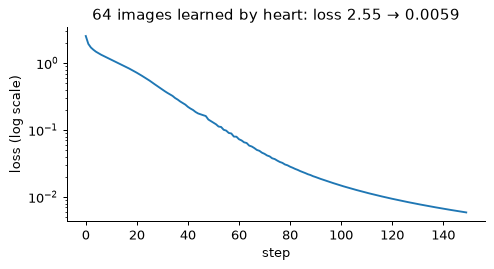

In [8]:
def learn_one_batch(cfg, steps=150, n=64):
    # Helper: train on the same 64 images again and again; return the loss after each step.
    torch.manual_seed(0)
    net = model.make_model(cfg)
    optimizer = torch.optim.AdamW(net.parameters(), lr=cfg.lr)
    x, y = tune_train.images[:n].float() / 255, tune_train.labels[:n]
    losses = []
    for _ in range(steps):
        loss = F.cross_entropy(net(x), y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    return losses


losses = learn_one_batch(start)
fig, ax = plt.subplots(figsize=(6, 2.8))
ax.semilogy(losses)
ax.set_xlabel("step")
ax.set_ylabel("loss (log scale)")
ax.set_title(f"64 images learned by heart: loss {losses[0]:.2f} → {losses[-1]:.4f}")
plt.show()

**Look at the augmentation.** Bugs in augmentation are silent: the network still trains,
just worse. We give one image to `flip_and_turn` 4,000 times. If it works, we see exactly 8
different results (4 quarter turns, each mirrored or not), each about 1/8 of the time.

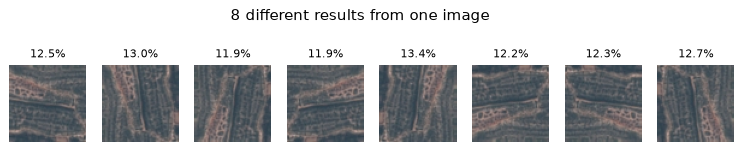

In [9]:
image = tune_train.images[3]  # an image that is not symmetric itself
results = model.flip_and_turn(image[None].repeat(4000, 1, 1, 1).float())
distinct, counts = results.flatten(1).unique(dim=0, return_counts=True)

fig, axes = plt.subplots(1, len(distinct), figsize=(1.3 * len(distinct), 1.8))
for ax, picture, count in zip(axes, distinct, counts, strict=True):
    ax.imshow(picture.view(3, 64, 64).permute(1, 2, 0) / 255)
    ax.set_title(f"{count / len(results):.1%}", fontsize=9)
    ax.axis("off")
fig.suptitle(f"{len(distinct)} different results from one image", y=1.08)
plt.show()

All three pass. The first loss is 2.48, a little above 2.30: the network starts slightly
opinionated, which is normal. It learns 64 images by heart (loss 2.55 → 0.006). And
`flip_and_turn` makes all 8 versions, each about 1/8 of the time.

**Learn more:** [A Recipe for Training Neural Networks](http://karpathy.github.io/2019/04/25/recipe/)
(Andrej Karpathy's blog: these checks and many more)

## 4 · Speed: what fits in 90 seconds on GitHub?

Training time is part of the budget, so we measure it *before* comparing settings: a setting
that is twice as slow gets half the epochs. We count **images per second**: how many
images a training step gets through (forward, loss, backward, update).

In [10]:
def speed(net, device, batch_size=128, augment=False):
    # Helper: training images per second on a device (the best of 3 tries).
    net = net.to(device)
    optimizer = torch.optim.AdamW(net.parameters())
    n = max(2048, 8 * batch_size)
    images, labels = tune_train.images[:n].to(device), tune_train.labels[:n].to(device)
    best = 0.0
    for _ in range(3):
        start_time = time.perf_counter()
        for x, y in zip(images.split(batch_size), labels.split(batch_size), strict=True):
            x = x.float() / 255
            if augment:
                x = model.flip_and_turn(x)
            loss = F.cross_entropy(net(x), y)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        loss.item()  # wait until the device has really finished
        best = max(best, n / (time.perf_counter() - start_time))
    return best


devices = ["cpu"] + (["mps"] if torch.backends.mps.is_available() else [])
device_speed = {d: speed(model.make_model(start), d, augment=True) for d in devices}
DEVICE = max(device_speed, key=device_speed.get)
for d, s in device_speed.items():
    print(f"{d:>4}: {s:7,.0f} images per second")
print(f"the experiments run on: {DEVICE}")

 cpu:   1,122 images per second
 mps:  15,969 images per second
the experiments run on: mps


The Mac's GPU trains this network about 14 times faster than its CPU, so the experiments run
there. GitHub has no GPU, so all *timing* is done on the CPU.

One surprise while building this notebook: turning images made the GPU 5 times slower.
`transpose` only changes how PyTorch *reads* a tensor, not where its numbers sit in memory,
and the GPU's convolutions are slow on such tensors. One `.contiguous()` at the end of
`flip_and_turn` fixed it. Measure; don't guess.

**From this computer to GitHub's.** The baseline trained 5 epochs of 19,440 images on
GitHub in 31.0, 36.6 and 43.0 seconds: the same code, three runs, so GitHub's machines vary
by about ±15%. We plan with the slowest. Then, for every network, we time it on this CPU
**right next to the baseline** and keep the ratio. A laptop's speed drifts (it heats up,
other programs run), and timing two things side by side cancels that out, while timing them
minutes apart does not.

In [11]:
GITHUB_BASELINE_SPEED = 5 * 19_440 / 43.0  # images per second: the baseline on GitHub
speed_vs_baseline = {}


def github_speed(cfg):
    # Helper: estimated images per second on GitHub. Only the network, the batch size and
    # augmentation change the speed, so each combination is timed once, next to the baseline.
    key = (cfg.widths, cfg.stem_stride, cfg.batch_norm, cfg.batch_size, cfg.augment)
    if key not in speed_vs_baseline:
        mine = speed(model.make_model(cfg), "cpu", cfg.batch_size, cfg.augment)
        speed_vs_baseline[key] = mine / speed(baseline(), "cpu")
    return GITHUB_BASELINE_SPEED * speed_vs_baseline[key]


def github_seconds(cfg):
    return cfg.epochs * (len(full) - cfg.valid_images) / github_speed(cfg)


def within_budget(cfg):
    # As many epochs as fit in the time budget.
    epochs = int(BUDGET_SECONDS * github_speed(cfg) / (len(full) - cfg.valid_images))
    return replace(cfg, epochs=epochs)


per_epoch = github_seconds(start) / start.epochs
print(f"starting point: {per_epoch:.1f} s per epoch on GitHub, so {within_budget(start).epochs} "
      f"epochs fit in {BUDGET_SECONDS} s")  # fmt: skip

starting point: 17.1 s per epoch on GitHub, so 5 epochs fit in 90 s


**Batch size and speed.** Bigger batches keep the computer busier, up to a point: tiny
batches waste time on overhead. But each step learns from one batch, so bigger batches also
mean fewer steps. Which matters more is a question for an experiment (section 7); this plot
shows the speed side.

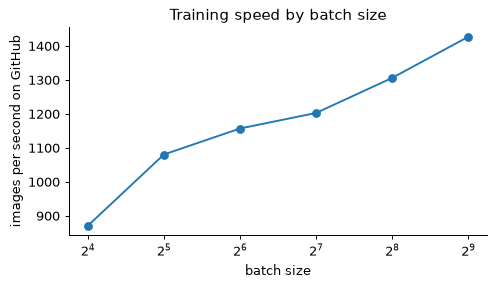

from here on: 5 epochs (what fits in 90 s)


In [12]:
batch_sizes = [16, 32, 64, 128, 256, 512]
throughput = pd.Series({b: github_speed(replace(start, batch_size=b)) for b in batch_sizes})
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(throughput.index, throughput.values, "o-")
ax.set_xscale("log", base=2)
ax.set_xlabel("batch size")
ax.set_ylabel("images per second on GitHub")
ax.set_title("Training speed by batch size")
plt.show()

base = within_budget(start)
print(f"from here on: {base.epochs} epochs (what fits in {BUDGET_SECONDS} s)")

Tiny batches are slow (16 images at a time: under 900 images per second), and speed keeps
growing with the batch size, but more and more slowly: from 32 to 128 it grows only about
10%. Whether the extra speed beats the extra steps is decided by accuracy, in section 7.

**Learn more:** [PyTorch internals](http://blog.ezyang.com/2019/05/pytorch-internals/)
(Edward Yang's blog: how tensors sit in memory, and what a "stride" is)

## 5 · How big is a difference by chance?

Train the same settings twice with different seeds and you get two different accuracies.
Before comparing settings we must know how big such luck is, or we will "discover" things
that are just noise. We train the same settings with 5 seeds. There is a second kind of
luck too: *which* 4,320 images happen to be in the check set.

In [13]:
class Curve:
    # Helper: plays GitHub's `log`. GitHub checks the logged model later, off the clock;
    # here time does not matter, so we check the validation images right away.

    def __init__(self):
        self.points, self.valid = [], None

    def validate_on(self, images, labels):
        self.valid = data.EuroSAT(images, labels)

    def __call__(self, net=None, **metrics):
        if net is not None:
            metrics |= {f"valid_{k}": v for k, v in measure(net, self.valid).items()}
        self.points.append(metrics)


@torch.no_grad()
def predict(net, images):
    # Helper: the network's 10 class scores for each image, fed the way the scorer does.
    net.eval()
    device = next(net.parameters()).device
    return torch.cat([net(x.to(device).float() / 255).cpu() for x in images.split(1000)])


def measure(net, dataset):
    scores = predict(net, dataset.images)
    return {"accuracy": (scores.argmax(1) == dataset.labels).float().mean().item(),
            "loss": F.cross_entropy(scores, dataset.labels).item()}  # fmt: skip


@dataclass
class Run:
    cfg: model.Config
    accuracy: float  # on the tune check images
    curve: list  # what train() logged, epoch by epoch
    net: nn.Module


RUNS = {}  # every training run, so running a cell again does not train again


def run(cfg, seed=0, train_set=tune_train):
    # Helper: train with these settings and this seed, then measure on the check images.
    key = (cfg, seed, len(train_set))
    if key not in RUNS:
        torch.manual_seed(seed)
        curve = Curve()
        net = model.train(train_set, curve, replace(cfg, device=DEVICE))
        RUNS[key] = Run(cfg, measure(net, tune_check)["accuracy"], curve.points, net)
    return RUNS[key]


def accuracy(cfg, seeds=(0, 1)):
    # The average over 2 seeds: less luck than a single run.
    return statistics.mean(run(cfg, seed).accuracy for seed in seeds)

In [14]:
seed_accuracies = [run(base, seed).accuracy for seed in range(5)]
seed_spread = statistics.stdev(seed_accuracies)
p = statistics.mean(seed_accuracies)
check_luck = 1.96 * math.sqrt(p * (1 - p) / len(tune_check))
# Two settings, each averaged over 2 seeds, differ by about one seed spread by luck alone.
# Twice that is our line between "real" and "maybe luck".
NOISE = 2 * seed_spread

print("same settings, 5 seeds:", ", ".join(f"{a:.1%}" for a in seed_accuracies))
print(f"typical difference between seeds: {seed_spread:.1%}")
print(f"luck of the check images: ±{check_luck:.1%}")
print(f"→ we treat differences under {NOISE:.1%} as ties")

same settings, 5 seeds: 85.6%, 84.4%, 85.6%, 84.9%, 84.1%
typical difference between seeds: 0.7%
luck of the check images: ±1.1%
→ we treat differences under 1.4% as ties


The same settings scored between 84.1% and 85.6%: one and a half points of pure luck. So we
call differences under 1.4 points ties. That is bigger than many "improvements" people
report, so remember it when you compare your own runs.

**Our rule from here on:** compare settings by their average over 2 seeds. A difference
smaller than `NOISE` is a **tie**, and a tie goes to the simpler or smaller option.

**Learn more:** [torch.manual_seed(3407) is all you need](https://arxiv.org/abs/2109.08203)
(a fun paper: how much the seed alone changes results) ·
[Deep Learning Tuning Playbook](https://github.com/google-research/tuning_playbook)
(Google's guide to tuning without fooling yourself)

## 6 · Learning rate

Training is like walking downhill in fog: you feel the slope under your feet and take a step.
The learning rate is the step size. Too small and you barely move in 90 seconds; too big and
you overshoot the valley and end up higher than before. It usually matters more than any
other setting, so it comes first. Two steps:

1. A **range test** finds the scale: a few hundred steps while raising the learning rate
   from tiny to huge, watching where the loss stops falling and shoots up.
2. A **sweep** tries values below that point, each with real training, and picks one.

`model.py` changes the step size during training (*one cycle*): it starts small, grows to the
learning rate, then shrinks to almost nothing, so the network settles at the end.

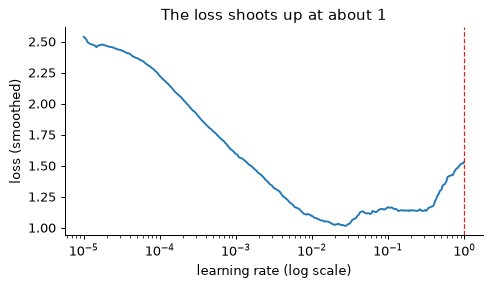

In [15]:
def range_test(cfg, low=1e-5, high=1.0, steps=300):
    # Helper: train while raising the learning rate; return the loss at each rate.
    torch.manual_seed(0)
    net = model.make_model(cfg).to(DEVICE)
    optimizer = torch.optim.AdamW(net.parameters(), weight_decay=cfg.weight_decay)
    images, labels = tune_train.images.to(DEVICE), tune_train.labels.to(DEVICE)
    losses = {}
    for lr in torch.logspace(math.log10(low), math.log10(high), steps).tolist():
        batch = torch.randint(len(images), (cfg.batch_size,), device=DEVICE)
        x = images[batch].float() / 255
        if cfg.augment:
            x = model.flip_and_turn(x)
        loss = F.cross_entropy(net(x), labels[batch])
        optimizer.param_groups[0]["lr"] = lr
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        losses[lr] = loss.item()
        if not loss.item() < 4 * min(losses.values()):  # blown up (or not a number)
            break
    return pd.Series(losses).ewm(alpha=0.05).mean()  # smoothed: single batches are noisy


smooth = range_test(base)
after_lowest = smooth[smooth.index > smooth.idxmin()]
too_high = after_lowest[after_lowest > 2 * smooth.min()]
blow_up = 10 ** round(math.log10(too_high.index.min() if len(too_high) else smooth.index.max()))

fig, ax = plt.subplots(figsize=(6, 3))
ax.semilogx(smooth.index, smooth.values)
ax.axvline(blow_up, color="tab:red", ls="--", lw=1)
ax.set_xlabel("learning rate (log scale)")
ax.set_ylabel("loss (smoothed)")
ax.set_title(f"The loss shoots up at about {blow_up:g}")
plt.show()

The sweep tries 7 learning rates, each about 3 times smaller than the last, from the
blow-up point down 1,000-fold. Each gets full training within the budget, twice (2 seeds).

Which one to pick? Often several are within noise of the best. We take the one **in the
middle of that good range**: if something shifts a little later (GitHub trains on more
images, another seed), a value in the middle stays good, while one at the edge may fall off.

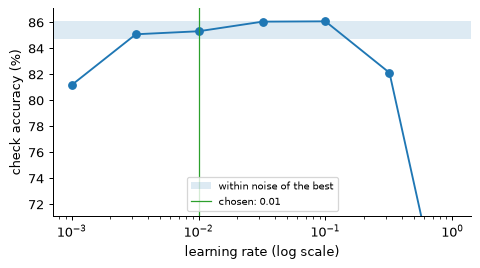

,epochs,accuracy
lr,,
0.001,5,0.812
0.003,5,0.851
0.010,5,0.853
0.032,5,0.861
0.100,5,0.861
0.320,5,0.821
1.000,5,0.603


In [16]:
LR_GRID = [float(f"{blow_up / 10 ** (k / 2):.2g}") for k in range(7)][::-1]


def sweep(cfg, name, values):
    # Helper: train with each value of one setting (2 seeds each); return the accuracies.
    rows = []
    for value in values:
        c = within_budget(replace(cfg, **{name: value}))
        rows.append({name: value, "epochs": c.epochs, "accuracy": accuracy(c)})
    return pd.DataFrame(rows).set_index(name)


GOOD = {}  # for each setting, every value the experiments found as good as the best


def good_values(table):
    return list(table.index[table.accuracy >= table.accuracy.max() - NOISE])


def middle_of_the_good_range(table):
    # The value in the middle (on a log scale) of those within noise of the best.
    good = good_values(table)
    middle = statistics.mean(math.log(v) for v in good)
    return min(table.index, key=lambda v: abs(math.log(v) - middle))


def plot_sweep(table, chosen, xlabel, base=10):
    fig, ax = plt.subplots(figsize=(6, 3))
    ax.plot(table.index, 100 * table.accuracy, "o-")
    ax.set_xscale("log", base=base)
    best = 100 * table.accuracy.max()
    ax.axhspan(best - 100 * NOISE, best, alpha=0.15, label="within noise of the best")
    ax.axvline(chosen, color="tab:green", lw=1, label=f"chosen: {chosen:g}")
    ax.set_ylim(max(ax.get_ylim()[0], best - 15), best + 1)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("check accuracy (%)")
    ax.legend(fontsize=8, loc="lower center")
    plt.show()


lr_table = sweep(base, "lr", LR_GRID)
base = replace(base, lr=middle_of_the_good_range(lr_table))
plot_sweep(lr_table, base.lr, "learning rate (log scale)")
lr_table

Too small (0.001) learns too slowly in 5 epochs; too big (0.32 and up) overshoots. Everything
from 0.003 to 0.1 is within noise of the best, and the middle of that range is **0.01**,
three times the baseline's.

**Learn more:** [Gradient descent, how neural networks learn](https://www.youtube.com/watch?v=IHZwWFHWa-w)
(3Blue1Brown video) · [The 1cycle policy](https://sgugger.github.io/the-1cycle-policy.html)
(Sylvain Gugger's blog: the range test and one-cycle, with pictures) ·
[Cyclical learning rates](https://arxiv.org/abs/1506.01186) and
[Super-convergence](https://arxiv.org/abs/1708.07120) (Leslie Smith's papers that started it)

## 7 · The shape of the network, at the same training time

The budget fixes the parameters *and* the time. So the fair question is: **in 90 seconds on
GitHub, which shape learns the most?** A network that is twice as fast gets twice the
epochs. All candidates stay under 26,522 parameters. They differ in two ways:

- **Stride 2 in the first layer** (notebook 1's idea): about 4 times less work, so about 3
  times the epochs. Does the lost fine detail matter more than the extra training?
- **Depth**: more, thinner blocks for the same parameters. Each block halves the image, so
  deeper blocks look at bigger areas of it.

In [17]:
shapes = {
    "3 blocks": dict(widths=(16, 32, 64), stem_stride=1),
    "3 blocks, stride 2": dict(widths=(16, 32, 64), stem_stride=2),
    "4 blocks": dict(widths=(16, 24, 32, 48), stem_stride=1),
    "4 blocks, stride 2": dict(widths=(16, 24, 32, 48), stem_stride=2),
    "5 blocks, stride 2": dict(widths=(12, 16, 24, 32, 40), stem_stride=2),
}
rows = []
for name, shape in shapes.items():
    cfg = within_budget(replace(base, **shape))
    assert parameters(cfg) <= BUDGET_PARAMETERS
    rows.append({"shape": name, "parameters": parameters(cfg),
                 "GitHub s per epoch": github_seconds(cfg) / cfg.epochs,
                 "epochs": cfg.epochs, "accuracy": accuracy(cfg), "cfg": cfg})  # fmt: skip
shape_table = pd.DataFrame(rows).set_index("shape")

ties = shape_table[shape_table.accuracy >= shape_table.accuracy.max() - NOISE]
chosen_shape = ties.parameters.idxmin()  # a tie goes to the smallest network
base = shape_table.cfg[chosen_shape]
GOOD["shape"] = [(c.widths, c.stem_stride) for c in ties.cfg]
print(f"within noise of the best: {', '.join(ties.index)} → chosen: {chosen_shape}")
shape_table.drop(columns="cfg")

within noise of the best: 4 blocks, stride 2 → chosen: 4 blocks, stride 2


,parameters,GitHub s per epoch,epochs,accuracy
shape,,,,
3 blocks,24346,17.124,5,0.853
"3 blocks, stride 2",24346,7.317,12,0.907
4 blocks,25354,15.979,5,0.884
"4 blocks, stride 2",25354,7.484,12,0.923
"5 blocks, stride 2",24598,7.130,12,0.905


**Stride 2 wins by a lot, at equal time.** Four blocks with stride 2 fit 12 epochs into 90
seconds and reach 92.3%; the same four blocks at full size fit only 5 epochs and reach 88.4%.
Fine detail was worth less than extra training, as notebook 1 suggested. Among the stride-2
networks, 4 blocks beat 3 and 5 by more than noise.

A new shape may prefer a different learning rate, so we sweep it again for the chosen one.

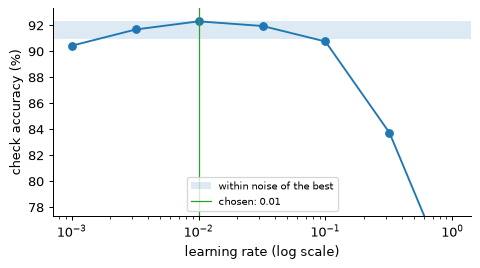

,epochs,accuracy
lr,,
0.001,12,0.904
0.003,12,0.917
0.010,12,0.923
0.032,12,0.920
0.100,12,0.908
0.320,12,0.837
1.000,12,0.722


In [18]:
lr_again = sweep(base, "lr", LR_GRID)
base = within_budget(replace(base, lr=middle_of_the_good_range(lr_again)))
GOOD["lr"] = good_values(lr_again)
plot_sweep(lr_again, base.lr, "learning rate (log scale)")
lr_again

For the new shape, 0.003 to 0.032 tie, and the middle is again **0.01**.

**Batch size**, now that shape and learning rate are set. Each size gets the epochs that fit
in 90 seconds, and we take the middle of the good range again.

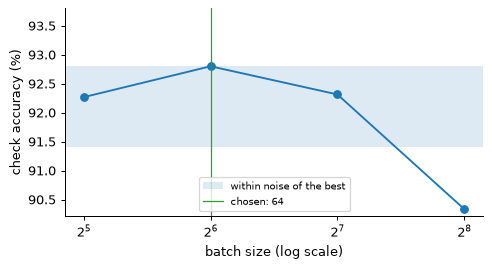

,epochs,accuracy
batch_size,,
32,10,0.923
64,11,0.928
128,12,0.923
256,10,0.903


In [19]:
batch_table = sweep(base, "batch_size", [32, 64, 128, 256])
base = within_budget(replace(base, batch_size=middle_of_the_good_range(batch_table)))
GOOD["batch_size"] = good_values(batch_table)
plot_sweep(batch_table, base.batch_size, "batch size (log scale)", base=2)
batch_table

Batches of 32, 64 and 128 tie (92.3% to 92.8%), and 256 falls behind (90.3%): fewer, bigger
steps are not enough in 90 seconds. The middle of the good range is **64**.

## 8 · Inside training: does batch normalization earn its place?

Batch normalization rescales each channel's outputs during training, so every layer
gets numbers of a similar size. It costs parameters (2 per channel) and time. To see what it
really does, we watch training from the inside.

PyTorch lets you attach small functions of your own to a model, called **hooks**, which run
every time a layer computes or the optimizer takes a step. `train()` hands us the model and
optimizer once, through `Config.watch`, and our `Probe` attaches its hooks. The training
code does not change at all. Every 10 steps, the probe records for each layer:

- **gradient size**: how strongly the loss pulls on the layer's weights;
- **update ratio**: how much the weights change in one step, compared to their size;
- **silent outputs**: the share of the layer's outputs that are exactly zero (ReLU turns
  negative numbers into zero);
- **dead channels**: channels that output zero for *every* image in the batch. A dead
  channel no longer learns: its parameters are wasted.

In [20]:
class Probe:
    # Helper: watches training through PyTorch hooks, without changing it.

    def __init__(self, every=10):
        self.every, self.step, self.rows = every, 0, []

    def __call__(self, net, optimizer):
        convs = [m for m in net.modules() if isinstance(m, nn.Conv2d)]
        self.weights = {f"conv{i}": m.weight for i, m in enumerate(convs, start=1)}
        self.weights["classify"] = next(m for m in net.modules() if isinstance(m, nn.Linear)).weight
        relus = [m for m in net.modules() if isinstance(m, nn.ReLU)]
        for i, relu in enumerate(relus, start=1):
            relu.register_forward_hook(self.after_relu(f"relu{i}"))
        optimizer.register_step_pre_hook(self.before_step)
        optimizer.register_step_post_hook(self.after_step)

    def now(self):
        return self.step % self.every == 0

    def record(self, layer, what, value):
        self.rows.append({"step": self.step, "layer": layer, "what": what, "value": value})

    def after_relu(self, name):
        def hook(module, inputs, output):
            if module.training and self.now():
                zero = output == 0
                self.record(name, "silent outputs", zero.float().mean().item())
                dead = zero.transpose(0, 1).flatten(1).all(1)  # zero for every image and pixel
                self.record(name, "dead channels", dead.float().mean().item())

        return hook

    def before_step(self, optimizer, args, kwargs):
        if self.now():
            self.before = {name: w.detach().clone() for name, w in self.weights.items()}
            for name, w in self.weights.items():
                self.record(name, "gradient size", w.grad.norm().item())

    def after_step(self, optimizer, args, kwargs):
        if self.now():
            for name, w in self.weights.items():
                change = (w.detach() - self.before[name]).norm() / self.before[name].norm()
                self.record(name, "update ratio", change.item())
        self.step += 1


def plot_probes(probes):
    # Helper: one column per probe, one row per measurement, one line per layer.
    whats = ["gradient size", "update ratio", "silent outputs", "dead channels"]
    fig, axes = plt.subplots(len(whats), len(probes), figsize=(5 * len(probes), 9),
                             sharex=True, sharey="row", squeeze=False)  # fmt: skip
    for column, (title, probe) in enumerate(probes.items()):
        table = pd.DataFrame(probe.rows)
        for row, what in enumerate(whats):
            ax = axes[row, column]
            for layer, part in table[table.what == what].groupby("layer", sort=False):
                ax.plot(part.step, part.value, label=layer, lw=1.2)
            if what in ("gradient size", "update ratio"):
                ax.set_yscale("log")
            ax.set_ylabel(what if column == 0 else "")
        axes[0, column].set_title(title)
        axes[-1, column].set_xlabel("step")
    for row in range(len(whats)):
        axes[row, -1].legend(fontsize=7, bbox_to_anchor=(1, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

Without batch normalization the best learning rate may differ, so it gets its own sweep.
Then one run of each is watched by a probe.

In [21]:
no_norm_lrs = sweep(replace(base, batch_norm=False), "lr", LR_GRID)
no_norm = within_budget(replace(base, batch_norm=False, lr=middle_of_the_good_range(no_norm_lrs)))
best_lr_for = {True: base.lr, False: no_norm.lr}  # by batch norm on or off

norm_table = pd.DataFrame([
    {"": "with batch norm", "lr": base.lr, "epochs": base.epochs,
     "parameters": parameters(base), "accuracy": accuracy(base)},
    {"": "without", "lr": no_norm.lr, "epochs": no_norm.epochs,
     "parameters": parameters(no_norm), "accuracy": accuracy(no_norm)},
]).set_index("")  # fmt: skip
norm_table

,lr,epochs,parameters,accuracy
,,,,
with batch norm,0.01,11,25354,0.928
without,0.01,11,25234,0.809


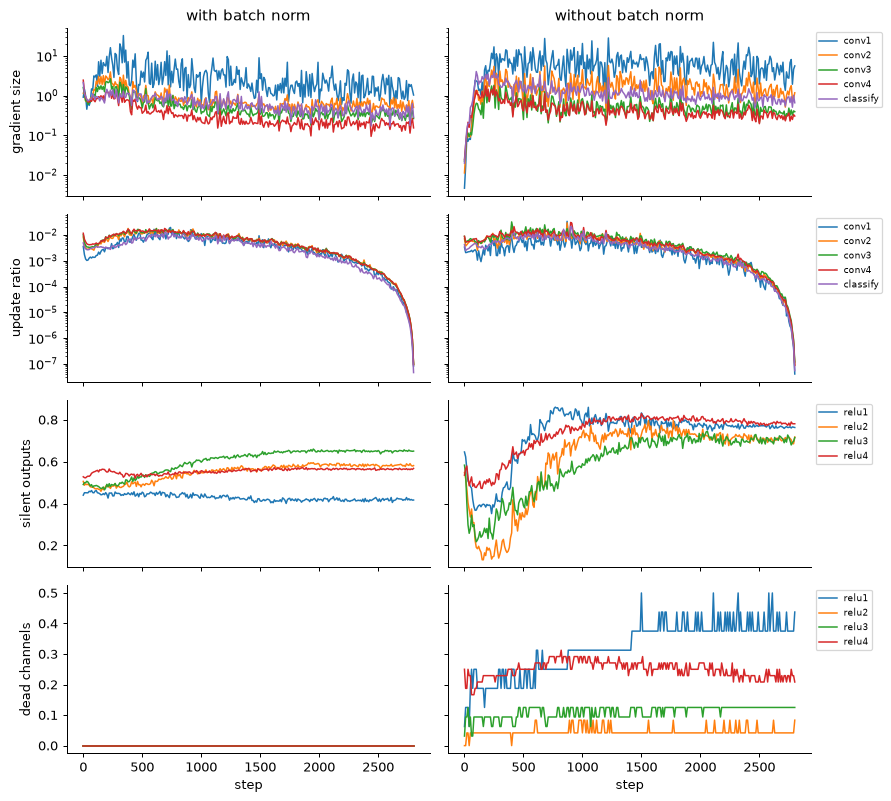

In [22]:
probes = {"with batch norm": Probe(), "without batch norm": Probe()}
run(replace(base, watch=probes["with batch norm"]))
run(replace(no_norm, watch=probes["without batch norm"]))
plot_probes(probes)

Without batch normalization the network loses **12 points** (80.9% against 92.8%), even with
its own best learning rate. The probe shows the main reason, in the bottom row: **dead
channels**. Without batch norm, up to 40% of the first block's channels, and a quarter of
the last block's, fall silent for every image and never come back. In a network this small,
that throws away a big part of its parameters. With batch norm, not a single channel dies.

In [23]:
gain = norm_table.accuracy["with batch norm"] - norm_table.accuracy["without"]
base = base if gain >= NOISE else no_norm
GOOD["batch_norm"] = [True] if gain >= NOISE else [False, True]
print(f"batch norm: {'yes' if base.batch_norm else 'no'} ({gain:+.1%})")

batch norm: yes (+11.9%)


**Learn more:** [Why does batch norm work?](https://www.youtube.com/watch?v=nUUqwaxLnWs)
(Andrew Ng, video) · [Babysitting the learning process](https://cs231n.github.io/neural-networks-3/)
(CS231n notes: update ratios and more) · the papers [Batch normalization](https://arxiv.org/abs/1502.03167)
and [How does batch normalization help?](https://arxiv.org/abs/1805.11604) (which argues the
first paper's explanation was wrong)

## 9 · Turning and mirroring: help or harm?

Notebook 1 found that the sunlight always comes from one side, so turned images are slightly
unreal. We measure two things:

1. **Accuracy**, trained with and without turning (each with its own epochs: turning costs
   a little time).
2. **How much each network cares about direction.** We turn and mirror the check images in
   all 8 ways and measure accuracy on each version. A network that learned something true
   only at one angle will do worse on the turned versions.

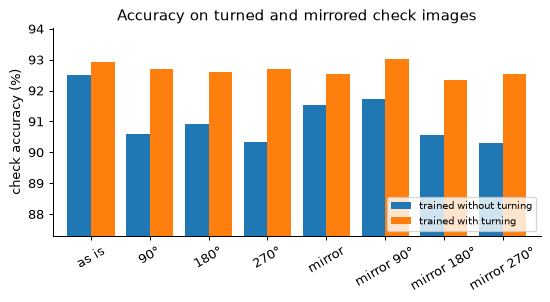

turning and mirroring: no (+0.2%)


,epochs,accuracy
,,
without turning,11,0.926
with turning,11,0.928


In [24]:
def symmetries(x):
    # Helper: the 8 turned and mirrored versions of a batch of images, in a fixed order.
    return [torch.rot90(m, k, (2, 3)) for m in (x, x.flip(3)) for k in range(4)]


views = ["as is", "90°", "180°", "270°", "mirror", "mirror 90°", "mirror 180°", "mirror 270°"]
plain = within_budget(replace(base, augment=False))
turned = within_budget(replace(base, augment=True))

by_view = pd.DataFrame({
    name: [measure(run(cfg).net, data.EuroSAT(v, tune_check.labels))["accuracy"]
           for v in symmetries(tune_check.images)]
    for name, cfg in {"trained without turning": plain, "trained with turning": turned}.items()
}, index=views)  # fmt: skip
ax = (100 * by_view).plot.bar(figsize=(7, 3), rot=30, width=0.8)
ax.set_ylim(100 * by_view.values.min() - 3, 100 * by_view.values.max() + 1)
ax.set_ylabel("check accuracy (%)")
ax.set_title("Accuracy on turned and mirrored check images")
ax.legend(fontsize=8, loc="lower right")
plt.show()

augment_table = pd.DataFrame([
    {"": "without turning", "epochs": plain.epochs, "accuracy": accuracy(plain)},
    {"": "with turning", "epochs": turned.epochs, "accuracy": accuracy(turned)},
]).set_index("")  # fmt: skip
gain = augment_table.accuracy["with turning"] - augment_table.accuracy["without turning"]
base = turned if gain >= NOISE else plain
GOOD["augment"] = [True] if gain >= NOISE else [False, True]
print(f"turning and mirroring: {'yes' if base.augment else 'no'} ({gain:+.1%})")
augment_table

Two different stories:

- **On images as they are**, the leftmost bars, both networks score the same (92.6% and
  92.8%): a tie. The test images are always "as they are".
- **On turned images**, the network trained without turning drops by up to 2 points: it
  learned some things that are only true one way up, like the direction of the light.
  The network trained with turning does equally well every way.

So turning made the network robust to something the test never asks for. In a tie our rule
picks the simpler option (off), and both are equally good. `model.py` keeps turning on,
because in other runs of this notebook, with a few more epochs, it was ahead by up to 1.7
points. Ties can fall either way from run to run: that is what "within noise" means.

**Memorizing, or not learning enough?** The training curves tell. If the network does much
better on its training images than on its validation images, it is **memorizing** them
(*overfitting*), and ways to discourage that would help. If both are about equal, it is too
small or too briefly trained (*underfitting*), and such brakes only slow it down.

*Weight decay* is one such brake: every step pulls all weights a little toward zero.

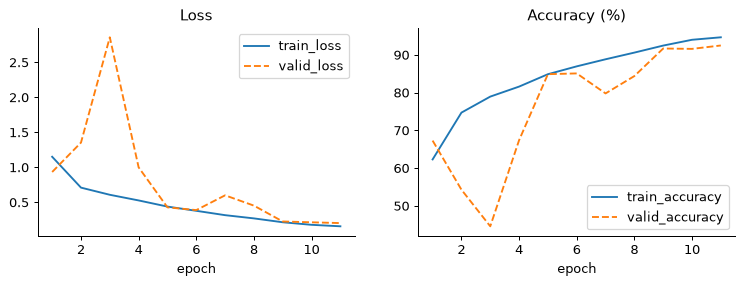

last epoch: training images 94.7%, validation images 92.5%


In [25]:
curve = pd.DataFrame(run(base).curve)
curve.index += 1
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
curve[["train_loss", "valid_loss"]].plot(ax=axes[0], style=["-", "--"], title="Loss")
(100 * curve[["train_accuracy", "valid_accuracy"]]).plot(
    ax=axes[1], style=["-", "--"], title="Accuracy (%)"
)
for ax in axes:
    ax.set_xlabel("epoch")
plt.show()
last = curve.iloc[-1]
print(f"last epoch: training images {last.train_accuracy:.1%}, "
      f"validation images {last.valid_accuracy:.1%}")  # fmt: skip

At the end, the training images score 94.7% and the validation images 92.5%, a gap of only 2
points. The network is not memorizing much; it is limited by its size and its 90 seconds.
(The training accuracy is measured on turned images, during the epoch, so it is a little
pessimistic.)

**Why is the dashed line so jumpy at first?** During training, batch norm rescales each
channel using the current batch. For checking, it uses *running averages* instead, which move
only 10% toward each new batch. While the learning rate is high, the weights change faster
than those averages can follow, so a check in the middle of training uses stale averages.
Our guess, to be tested: the network is fine, only the averages lag. If so, recomputing
them from training images just before each check should close the gap.

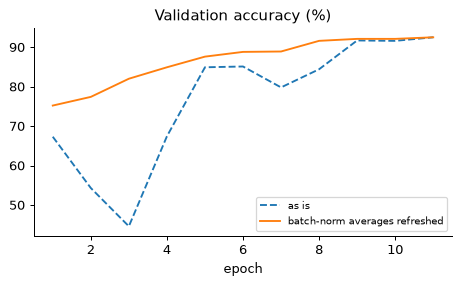

In [26]:
@torch.no_grad()
def refresh_batch_norm(net):
    # Helper: a copy of the network with its batch-norm averages recomputed from training images.
    net = copy.deepcopy(net)
    for m in net.modules():
        if isinstance(m, nn.BatchNorm2d):
            m.reset_running_stats()
            m.momentum = None  # a plain average over the batches below
    net.train()
    device = next(net.parameters()).device
    for x in tune_train.images[:4096].split(256):
        net(x.to(device).float() / 255)
    return net


class CurveWithRefresh(Curve):
    # Helper: also checks a refreshed copy at every epoch.
    def __call__(self, net=None, **metrics):
        super().__call__(net, **metrics)
        refreshed = measure(refresh_batch_norm(net), self.valid)["accuracy"]
        self.points[-1]["valid_accuracy_refreshed"] = refreshed


torch.manual_seed(0)
log = CurveWithRefresh()
model.train(tune_train, log, replace(base, device=DEVICE))
lag = 100 * pd.DataFrame(log.points)[["valid_accuracy", "valid_accuracy_refreshed"]]
lag.index += 1
ax = lag.plot(style=["--", "-"], figsize=(6, 3), title="Validation accuracy (%)")
ax.legend(["as is", "batch-norm averages refreshed"], fontsize=8)
ax.set_xlabel("epoch")
plt.show()

Confirmed. With refreshed averages, validation accuracy climbs smoothly (75% after one
epoch), while the stored averages drop as low as 45% at epoch 3. The network was fine all
along; only the averages lagged. They catch up at the end, when the learning rate is tiny,
so the final model is not affected.

**Lesson:** with batch norm, don't trust validation numbers in the middle of training, and
don't stop training early because of them.

In [27]:
decay_table = sweep(base, "weight_decay", [0.0, 0.01, 0.1])
gain = decay_table.accuracy.max() - decay_table.accuracy[0.0]
base = within_budget(
    replace(base, weight_decay=decay_table.accuracy.idxmax() if gain >= NOISE else 0.0)
)
GOOD["weight_decay"] = good_values(decay_table)
print(f"weight decay: {base.weight_decay}")
decay_table

weight decay: 0.0


,epochs,accuracy
weight_decay,,
0.00,11,0.926
0.01,11,0.925
0.10,11,0.926


Weight decay changes nothing (92.5% to 92.6%): there is little memorizing to prevent. It
stays off.

**Learn more:** [Overfitting](https://developers.google.com/machine-learning/crash-course/overfitting/overfitting)
(Google's crash course) · [Decoupled weight decay](https://arxiv.org/abs/1711.05101) (the paper
behind AdamW, the optimizer in `model.py`)

## 10 · Would more time or more data help?

Two questions to ask any model before giving it more of either:

- **More time:** the same settings with half and twice the epochs.
- **More data:** the same number of steps, learning from 1/8, 1/4 and 1/2 of the images.
  The slope says what more images would be worth, and what keeping 1,000 aside for the
  validation curve costs.

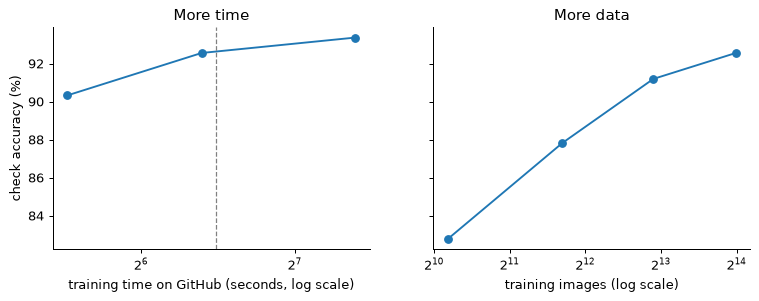

the last doubling of the images added +1.4%
→ keeping 1,000 of 21,600 images aside costs about 0.09%


In [28]:
time_rows = []
for factor in (0.5, 1, 2):
    cfg = replace(base, epochs=round(base.epochs * factor))
    time_rows.append({"GitHub seconds": github_seconds(cfg), "epochs": cfg.epochs,
                      "accuracy": accuracy(cfg)})  # fmt: skip
time_table = pd.DataFrame(time_rows)

order = torch.randperm(len(tune_train), generator=torch.Generator().manual_seed(0))
data_rows = []
for share in (1 / 8, 1 / 4, 1 / 2, 1):
    part = tune_train.subset(order[: round(share * len(tune_train))])
    cfg = replace(base, epochs=round(base.epochs / share))  # the same number of steps
    mean = statistics.mean(run(cfg, seed, part).accuracy for seed in (0, 1))
    data_rows.append(
        {"images": len(part) - cfg.valid_images, "epochs": cfg.epochs, "accuracy": mean}
    )
data_table = pd.DataFrame(data_rows)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
axes[0].plot(time_table["GitHub seconds"], 100 * time_table.accuracy, "o-")
axes[0].axvline(BUDGET_SECONDS, color="gray", ls="--", lw=1)
axes[0].set_xscale("log", base=2)
axes[0].set_xlabel("training time on GitHub (seconds, log scale)")
axes[0].set_ylabel("check accuracy (%)")
axes[0].set_title("More time")
axes[1].plot(data_table.images, 100 * data_table.accuracy, "o-")
axes[1].set_xscale("log", base=2)
axes[1].set_xlabel("training images (log scale)")
axes[1].set_title("More data")
plt.show()

per_doubling = data_table.accuracy.iloc[-1] - data_table.accuracy.iloc[-2]
holdout_cost = per_doubling * math.log2(len(full) / (len(full) - base.valid_images))
print(f"the last doubling of the images added {per_doubling:+.1%}")
print(
    f"→ keeping {base.valid_images:,} of {len(full):,} images aside costs about {holdout_cost:.2%}"
)

- **More time helps, but less and less:** half the time costs 2 points; twice the time gains
  less than 1.
- **More data helps steadily:** each doubling of the images added 5, then 3.4, then 1.4
  points, and the curve has not flattened. This network would still learn from more images.
  Keeping 1,000 images aside for the validation curve costs about 0.1 point, so we keep them.

For your own submission: you have 10 minutes, not 90 seconds, and no parameter budget. A
bigger network trained longer is the obvious next step.

**Learn more:** [Deep learning scaling is predictable](https://arxiv.org/abs/1712.00409) (a
paper on how accuracy grows with data, for the curious)

## 11 · The chosen model: where does it fail?

The chosen settings, trained on the tune split. Accuracy alone hides *which* mistakes the
network makes. Three views show them.

check accuracy: 92.5%   (the baseline: 76.3% on the test images)


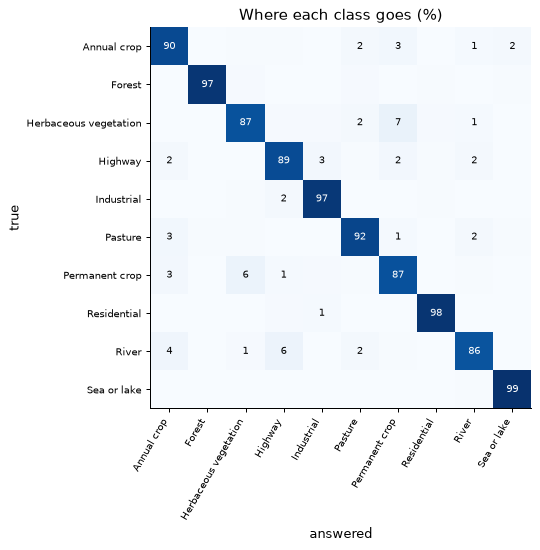

In [29]:
final = run(base)
scores = predict(final.net, tune_check.images)
guess = scores.argmax(1)
names = data.CLASSES
print(f"check accuracy: {final.accuracy:.1%}   (the baseline: 76.3% on the test images)")

# Helper: the confusion matrix, in percent of each row (each true class).
matrix = torch.zeros(10, 10).index_put_(
    (tune_check.labels, guess), torch.ones(len(guess)), accumulate=True
)
matrix = 100 * matrix / matrix.sum(1, keepdim=True)
fig, ax = plt.subplots(figsize=(6, 5.5))
ax.imshow(matrix, cmap="Blues", vmin=0, vmax=100)
for i in range(10):
    for j in range(10):
        if matrix[i, j] >= 1:
            ax.text(j, i, f"{matrix[i, j]:.0f}", ha="center", va="center", fontsize=8,
                    color="white" if matrix[i, j] > 50 else "black")  # fmt: skip
ax.set_xticks(range(10), names, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(10), names, fontsize=8)
ax.set_xlabel("answered")
ax.set_ylabel("true")
ax.set_title("Where each class goes (%)")
plt.show()

**The most confident mistakes.** The check images where the network was most sure, and
wrong. Some are real mistakes; some may have a debatable label.

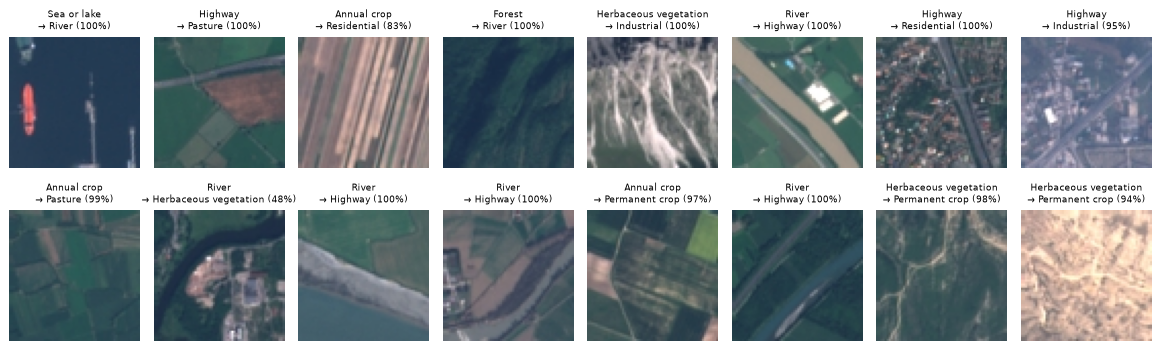

In [30]:
losses = F.cross_entropy(scores, tune_check.labels, reduction="none")
worst = losses.argsort(descending=True)[:16]
confidence = F.softmax(scores, 1).max(1).values
fig, axes = plt.subplots(2, 8, figsize=(13, 4.2))
for ax, i in zip(axes.flat, worst.tolist(), strict=True):
    ax.imshow(tune_check.images[i].permute(1, 2, 0))
    ax.set_title(f"{names[tune_check.labels[i]]}\n→ {names[guess[i]]} ({confidence[i]:.0%})",
                 fontsize=7)  # fmt: skip
    ax.axis("off")
plt.tight_layout()
plt.show()

**What does the network look at?** Hide one square of the image at a time (painted in the
image's average color) and see how much the network's belief in the true class drops. Red:
hiding this spot hurts the right answer, so the network relies on it. Blue: hiding it helps.

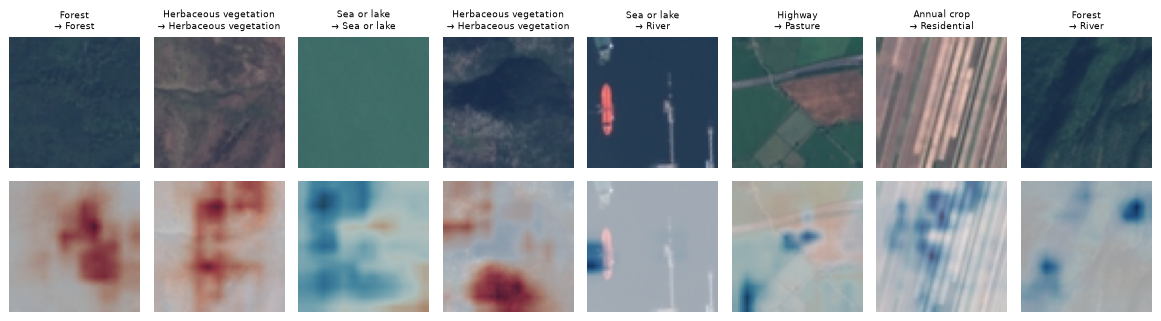

In [31]:
@torch.no_grad()
def occlusion(net, image, label, patch=16, stride=4):
    # Helper: how much hiding each spot lowers the probability of the true class.
    net.eval()
    device = next(net.parameters()).device
    x = image.float()[None] / 255
    spots = range(0, 64 - patch + 1, stride)
    hidden = []
    for top in spots:
        for left in spots:
            h = x.clone()
            h[..., top : top + patch, left : left + patch] = x.mean((2, 3), keepdim=True)
            hidden.append(h)
    p = F.softmax(net(torch.cat([x, *hidden]).to(device)), 1)[:, label].cpu()
    drop = (p[0] - p[1:]).view(1, 1, len(spots), len(spots))
    return F.interpolate(drop, size=64, mode="bilinear")[0, 0]


right = (guess == tune_check.labels).nonzero().flatten()
examples = [right[k * 300].item() for k in range(4)] + worst[:4].tolist()
fig, axes = plt.subplots(2, 8, figsize=(13, 3.8))
for column, i in enumerate(examples):
    label = tune_check.labels[i].item()
    axes[0, column].imshow(tune_check.images[i].permute(1, 2, 0))
    axes[0, column].set_title(f"{names[label]}\n→ {names[guess[i]]}", fontsize=7)
    heat = occlusion(final.net, tune_check.images[i], label)
    limit = heat.abs().max().item() or 1
    axes[1, column].imshow(tune_check.images[i].permute(1, 2, 0))
    axes[1, column].imshow(heat, cmap="RdBu_r", vmin=-limit, vmax=limit, alpha=0.6)
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

The mix-ups match notebook 1's suspects: **Herbaceous vegetation ↔ Permanent crop** (fields
with similar patterns) and **River → Highway** (long straight lines).

The most confident mistakes are worth a close look: straight canals and riverbanks called
Highway, a lake with a ship called River, a dark forest valley called River. Some labels are
debatable: one "Highway" is mostly a town around a highway.

In the occlusion maps, right answers rely on texture spread over the image (red). In the
mistakes, blue shows what misled the network: hiding the ship makes it believe more in
"Sea or lake".

**Learn more:** [Visualizing and understanding convolutional networks](https://arxiv.org/abs/1311.2901)
(the paper behind hiding squares) · [Feature visualization](https://distill.pub/2017/feature-visualization/)
(Distill: beautiful pictures of what networks see)

**An idea we measure but do not use: asking 8 times.** Show the network all 8 turned and
mirrored versions of each image and average its answers (*test-time augmentation*). It costs
8 times the work per image, which the leaderboard shows as compute per image, so we leave it
to you.

In [32]:
probabilities = [F.softmax(predict(final.net, v), 1) for v in symmetries(tune_check.images)]
eight = (torch.stack(probabilities).mean(0).argmax(1) == tune_check.labels).float().mean().item()
print(
    f"one answer: {final.accuracy:.1%}, average of 8: {eight:.1%} ({eight - final.accuracy:+.1%})"
)

one answer: 92.5%, average of 8: 93.0% (+0.5%)


## 12 · What each choice bought

Each row undoes one decision and keeps all the others (with as many epochs as fit in 90
seconds). The difference from "chosen" is what that decision is worth. This is called an
*ablation*. Most rows were trained above and come from `RUNS`.

In [33]:
variants = {
    "chosen": base,
    "the baseline's learning rate (0.003)": within_budget(replace(base, lr=0.003)),
    "the baseline's batch size (128)": within_budget(replace(base, batch_size=128)),
    "first layer at full size (stride 1)": within_budget(replace(base, stem_stride=1)),
    "batch norm switched": within_budget(
        replace(base, batch_norm=not base.batch_norm, lr=best_lr_for[not base.batch_norm])
    ),
    "turning switched": within_budget(replace(base, augment=not base.augment)),
    "the starting point": within_budget(start),
}
ablation = pd.DataFrame([
    {"variant": name, "parameters": parameters(c), "epochs": c.epochs,
     "GitHub s": round(github_seconds(c)), "accuracy": accuracy(c)}
    for name, c in variants.items()
]).set_index("variant")  # fmt: skip
ablation["vs chosen"] = ablation.accuracy - ablation.accuracy["chosen"]
ablation

,parameters,epochs,GitHub s,accuracy,vs chosen
variant,,,,,
chosen,25354,11,84,0.926,0.000e+00
the baseline's learning rate (0.003),25354,11,84,0.925,-5.787e-04
the baseline's batch size (128),25354,10,86,0.914,-1.123e-02
first layer at full size (stride 1),25354,4,73,0.894,-3.160e-02
batch norm switched,25234,11,83,0.820,-1.052e-01
turning switched,25354,11,87,0.928,2.431e-03
the starting point,24346,5,86,0.850,-7.569e-02


Only two decisions matter by more than noise: **batch normalization** (10.5 points) and
**stride 2** (3.2 points). The learning rate, the batch size and turning each moved the
score by less than the noise here; the learning rate mattered a lot in section 6, but by now
the network sits on a wide plateau where any value from 0.003 to 0.032 works. All together,
the choices turned the starting point (85.0%) into 92.6%, with the same budget.

## 13 · Submit

**Do the defaults in `model.py` agree with the experiments?** GitHub uses the defaults, so
they must. Several values are often equally good (within noise), so a default passes if the
experiments found it as good as the best, not only if it is the exact value they picked.
Epochs pass within one of the estimate, because they come from timing this computer.

In [34]:
d = model.Config()
rows = [
    ("shape", (d.widths, d.stem_stride), (base.widths, base.stem_stride), GOOD["shape"]),
    ("learning rate", d.lr, base.lr, GOOD["lr"]),
    ("batch size", d.batch_size, base.batch_size, GOOD["batch_size"]),
    ("batch norm", d.batch_norm, base.batch_norm, GOOD["batch_norm"]),
    ("turning", d.augment, base.augment, GOOD["augment"]),
    ("weight decay", d.weight_decay, base.weight_decay, GOOD["weight_decay"]),
    ("validation images", d.valid_images, base.valid_images, [base.valid_images]),
]
check = pd.DataFrame(
    [
        {"setting": n, "model.py": m, "picked here": p, "as good": g, "ok": m in g}
        for n, m, p, g in rows
    ]
).set_index("setting")
fits = within_budget(d).epochs
verdict = "ok" if abs(d.epochs - fits) <= 1 else "NOT ok"
print(f"model.py: {parameters(d):,} parameters, {d.epochs} epochs ({fits} fit in "
      f"{BUDGET_SECONDS} s: {verdict}), about {github_seconds(d):.0f} s on GitHub")  # fmt: skip
check

model.py: 25,354 parameters, 11 epochs (11 fit in 90 s: ok), about 87 s on GitHub


,model.py,picked here,as good,ok
setting,,,,
shape,"((16, 24, 32, 48), 2)","((16, 24, 32, 48), 2)","[((16, 24, 32, 48), 2)]",True
learning rate,0.01,0.01,"[0.003, 0.01, 0.032]",True
batch size,64,64,"[32, 64, 128]",True
batch norm,True,True,[True],True
turning,True,False,"[False, True]",True
weight decay,0.0,0.0,"[0.0, 0.01, 0.1]",True
validation images,1000,1000,[1000],True


**The confirmation.** `uv run score` trains `model.py` exactly as GitHub will, on the CPU, and
checks it on the `seed=7` split: images that played no part in any choice above.

In [35]:
!uv run score .

Checked the logged models in 3 seconds (not training time).



Submission:     demo
Check accuracy: 92.08% (on held-back training images)
Parameters:     25,354
Model size:     102 kB
Training time:  102 seconds
Accuracy by class:
  Annual crop             89.4%  ##################
  Forest                  99.0%  ####################
  Herbaceous vegetation   87.0%  #################
  Highway                 86.7%  #################
  Industrial              95.5%  ###################
  Pasture                 89.1%  ##################
  Permanent crop          89.2%  ##################
  Residential             98.4%  ####################
  River                   84.7%  #################
  Sea or lake             97.7%  ####################
Most common mix-ups (true -> answered):
  River -> Highway: 30 images
  Herbaceous vegetation -> Permanent crop: 30 images
  Permanent crop -> Herbaceous vegetation: 18 images


On images that played no part in any choice, the demo scores **92.1%**. The baseline scores
78.1% on the same images: **14 points better, with fewer parameters**. The training time
printed above is this laptop's CPU; GitHub reports its own on the pull request.

**What we did not tune, and why:**

- The optimizer (AdamW, with PyTorch's defaults) and the shape of the one-cycle schedule:
  the learning rate matters far more, and we tuned that.
- 3×3 windows and max pooling: standard choices, and a 26,522-parameter budget leaves little
  room to play.
- Dropout and other brakes: the network barely memorizes (section 9).
- Color changes: notebook 1 showed that color carries a lot of the answer.

**Ideas for your own submission**, with evidence from this notebook:

- **Train longer.** You have 10 minutes; section 10 shows more time still helps.
- **Grow the network.** You do not have our parameter budget.
- **Answer 8 times** (test-time augmentation): +0.5 points here, at 8 times the work per image.
- **Study the mistakes.** River against Highway and the four field classes are where the
  points are.